Kích thước ban đầu: (20640, 10)

Số ô bị trống ở mỗi cột:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ---
Sai số MSE: 4,802,173,538.60
Điểm R^2 score: 0.6488


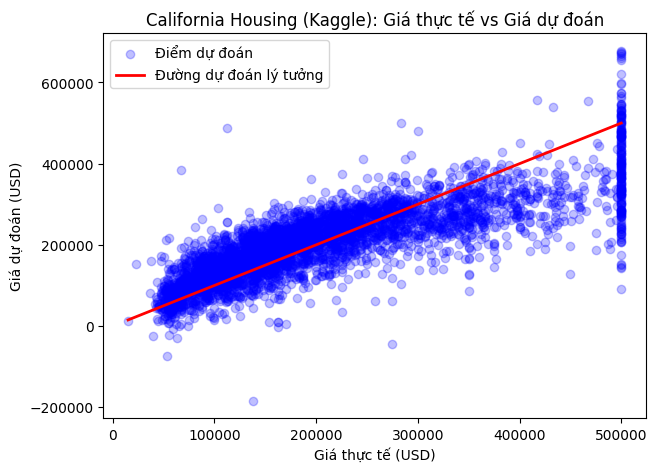

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('housing.csv')
print("Kích thước ban đầu:", df.shape)
print("\nSố ô bị trống ở mỗi cột:")
print(df.isnull().sum())
df_clean = df.dropna()

df_clean = pd.get_dummies(df_clean, columns=['ocean_proximity'], drop_first=True)

X = df_clean.drop(columns=['median_house_value'])
y = df_clean['median_house_value']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ---")
print(f"Sai số MSE: {mse:,.2f}")
print(f"Điểm R^2 score: {r2:.4f}")

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, color="blue", alpha=0.25, label="Điểm dự đoán")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linewidth=2, label="Đường dự đoán lý tưởng")
plt.title("California Housing (Kaggle): Giá thực tế vs Giá dự đoán")
plt.xlabel("Giá thực tế (USD)")
plt.ylabel("Giá dự đoán (USD)")
plt.legend()
plt.show()